# Phase I

This notebook contains the threshold trade off graph for the RoBERTa hate speech classifier.

 It uses the stored model scores and reference labels to show how the **false positive rate (FPR)** and **false negative rate (FNR)** change when the decision threshold changes.

- A **false positive** is a non-hateful example incorrectly classified as hateful.
- A **false negative** is a hateful example incorrectly classified as non hateful.
- The two datasets are shown with different colors.
- Solid lines represent FPR; dashed lines represent FNR.

In [8]:
# Imports and file locations
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.colors import qualitative

DATA_DIR = os.environ.get("DATA_DIR", "")
SEARCH_DIRS = []
if DATA_DIR:
    SEARCH_DIRS.append(Path(DATA_DIR))
SEARCH_DIRS.extend([Path.cwd(), Path.cwd() / "data", Path("/content"), Path("/data")])
SEARCH_DIRS = list(dict.fromkeys(path for path in SEARCH_DIRS if path.exists()))

TOXIGEN_FILE = "toxigen_processed_scored_final.csv"
MHS_FILE = "mhs_5groups_2500_results_final.csv"

def find_file(filename):
    for directory in SEARCH_DIRS:
        candidate = directory / filename
        if candidate.exists():
            return candidate
    return None

toxigen_path = find_file(TOXIGEN_FILE)
mhs_path = find_file(MHS_FILE)

if toxigen_path is None or mhs_path is None:
    missing = [name for name, path in [(TOXIGEN_FILE, toxigen_path), (MHS_FILE, mhs_path)] if path is None]
    raise FileNotFoundError(
        "Missing file(s): " + ", ".join(missing) +
        ". Put the CSV files beside the notebook, under ./data or /content, "
        "or set DATA_DIR to their folder."
    )

print("ToxiGen:", toxigen_path)
print("MHS:", mhs_path)

ToxiGen: /content/toxigen_processed_scored_final.csv
MHS: /content/mhs_5groups_2500_results_final.csv


In [9]:
# Load only the columns needed for the threshold-tradeoff graph.
toxigen = pd.read_csv(toxigen_path, usecols=["true_label", "pred_label", "hate_prob", "toxicity_human"])
mhs = pd.read_csv(mhs_path, usecols=["true_label", "pred_label", "prob_hate", "hate_speech_score"])

toxigen = toxigen.rename(columns={"hate_prob": "score"})
mhs = mhs.rename(columns={"prob_hate": "score"})

toxigen["dataset"] = "ToxiGen"
mhs["dataset"] = "MHS"

df = pd.concat(
    [toxigen[["dataset", "true_label", "pred_label", "score"]],
     mhs[["dataset", "true_label", "pred_label", "score"]]],
    ignore_index=True,
)
df = df.rename(columns={"true_label": "true", "pred_label": "pred"})
df["true"] = pd.to_numeric(df["true"], errors="raise").astype(int)
df["pred"] = pd.to_numeric(df["pred"], errors="raise").astype(int)
df["score"] = pd.to_numeric(df["score"], errors="raise").clip(0, 1)

required = {"dataset", "true", "pred", "score"}
missing = required.difference(df.columns)
if missing:
    raise ValueError(f"Missing required harmonized columns: {sorted(missing)}")

print(f"Rows used: {len(df):,}")
print(df.groupby("dataset", observed=True).size().to_string())

Rows used: 4,800
dataset
MHS        2500
ToxiGen    2300


In [10]:
def threshold_tradeoff_fig(df: pd.DataFrame, thresholds: np.ndarray | None = None) -> go.Figure:

    thresholds = np.linspace(0.05, 0.95, 19) if thresholds is None else thresholds
    palette = qualitative.Plotly
    fig = go.Figure()

    for i, (dataset, sub) in enumerate(df.groupby("dataset", observed=True)):
        neg, pos = (sub.true == 0).to_numpy(), (sub.true == 1).to_numpy()
        n_neg, n_pos = max(neg.sum(), 1), max(pos.sum(), 1)
        s = sub.score.to_numpy()

        # Vectorized over thresholds (no sklearn needed for FPR/FNR)
        pred = s[None, :] >= thresholds[:, None]            # (T, N)
        fpr = (pred & neg).sum(axis=1) / n_neg
        fnr = (~pred & pos).sum(axis=1) / n_pos

        color = palette[i % len(palette)]
        fig.add_trace(go.Scatter(
            x=thresholds, y=fpr, mode="lines+markers", name=f"{dataset} FPR",
            legendgroup=str(dataset), line=dict(color=color),
            hovertemplate="FPR=%{y:.3f}<extra>" + str(dataset) + "</extra>"))
        fig.add_trace(go.Scatter(
            x=thresholds, y=fnr, mode="lines+markers", name=f"{dataset} FNR",
            legendgroup=str(dataset), line=dict(color=color, dash="dash"),
            marker=dict(symbol="diamond"),
            hovertemplate="FNR=%{y:.3f}<extra>" + str(dataset) + "</extra>"))

    fig.update_layout(
        title="Threshold trade-off: FPR solid, FNR dashed",
        xaxis_title="threshold", yaxis_title="rate",
        yaxis=dict(range=[0, 1.02]), hovermode="x unified",
        template="plotly_white", height=450,
    )
    return fig

threshold_tradeoff_fig(df).show()
print("Supplied prediction agreement with score >= .5:",
      round((df.pred == (df.score >= .5).astype(int)).mean(), 3))

Supplied prediction agreement with score >= .5: 1.0


## Graph 2: Model score versus human rating

Each panel compares a human rating on the x axis with the model's hate score on the y axis. Points are colored by prediction status: correct predictions, false alarms (false positives), and missed hate (false negatives). The vertical and horizontal dashed lines show the human rating boundary and model score boundary. Together, they create four interpretable regions: FP, FN, TN, and TP.

In [11]:
# Prepare the two datasets for the score-versus-human-rating graph.
ai_df = toxigen.copy()
human_df = mhs.copy()

ai_df["rating"] = ai_df["toxicity_human"]       # 1-5; human boundary = 3.
ai_df["score"] = ai_df["score"]
ai_df["x"] = ai_df["rating"] + np.random.default_rng(0).uniform(-0.12, 0.12, len(ai_df))

human_df["rating"] = human_df["hate_speech_score"]  # continuous; human boundary = 0.5.
human_df["score"] = human_df["score"]
human_df["x"] = human_df["rating"]

panels = [
    (
        "AI-generated (ToxiGen)",
        ai_df,
        3.0,
        "Human rating: toxicity_human (1 = harmless, 5 = very harmful)",
    ),
    (
        "Human-written (MHS)",
        human_df,
        0.5,
        "Human rating: hate_speech_score (< -1 supportive, > 0.5 hate)",
    ),
]

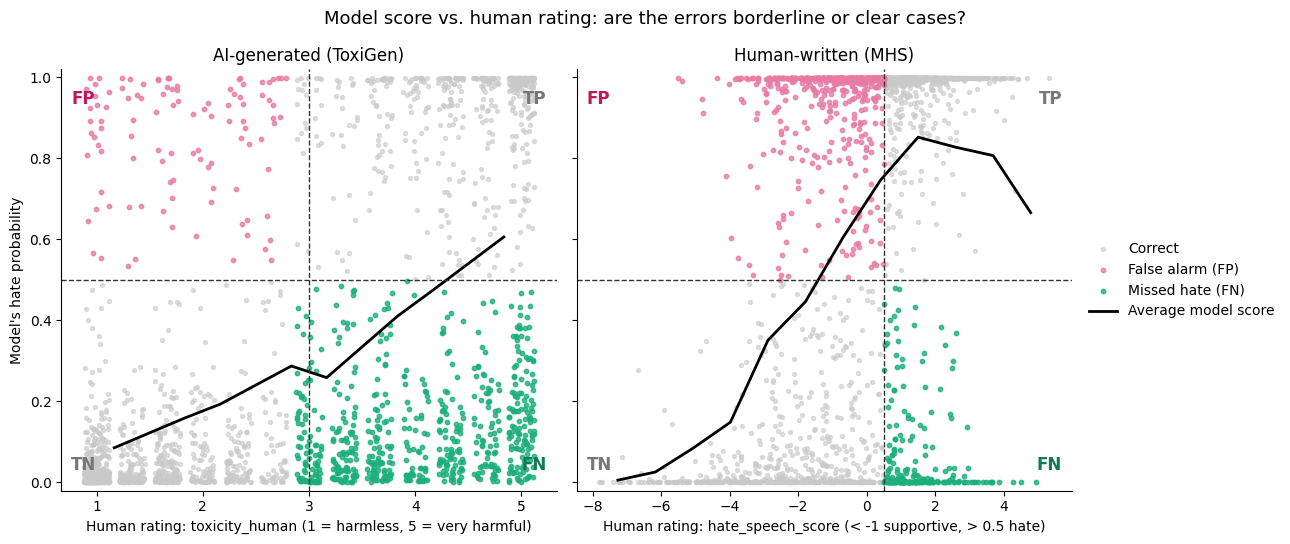

In [12]:
# Plot model score versus human rating, with error categories and confusion regions.
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)

for ax, (title, data, label_threshold, xlabel) in zip(axes, panels):
    correct = data[data["true_label"] == data["pred_label"]]
    fp = data[(data["true_label"] == 0) & (data["pred_label"] == 1)]
    fn = data[(data["true_label"] == 1) & (data["pred_label"] == 0)]

    ax.scatter(correct["x"], correct["score"], s=8, color="#c9c9c9", alpha=0.6, label="Correct")
    ax.scatter(fp["x"], fp["score"], s=10, color="#e87ba4", alpha=0.8, label="False alarm (FP)")
    ax.scatter(fn["x"], fn["score"], s=10, color="#1baf7a", alpha=0.8, label="Missed hate (FN)")

    # Average model score within 12 human-rating bins.
    bin_edges = np.linspace(data["rating"].min(), data["rating"].max(), 13)
    binned = data.assign(rating_bin=pd.cut(data["rating"], bin_edges, include_lowest=True))
    means = binned.groupby("rating_bin", observed=True)["score"].mean()
    centers = [interval.mid for interval in means.index]
    ax.plot(centers, means.values, color="black", linewidth=2, label="Average model score")

    # Human-rating threshold and model-score threshold.
    ax.axvline(label_threshold, color="#333333", linestyle="--", linewidth=1)
    ax.axhline(0.5, color="#333333", linestyle="--", linewidth=1)

    left, right = ax.get_xlim()
    ax.text(left + 0.02 * (right - left), 0.97, "FP", fontsize=12, fontweight="bold", va="top", color="#c2185b")
    ax.text(right - 0.02 * (right - left), 0.03, "FN", fontsize=12, fontweight="bold", ha="right", color="#0f7a54")
    ax.text(left + 0.02 * (right - left), 0.03, "TN", fontsize=12, fontweight="bold", color="#777777")
    ax.text(right - 0.02 * (right - left), 0.97, "TP", fontsize=12, fontweight="bold", ha="right", va="top", color="#777777")

    ax.set_title(title, fontsize=12)
    ax.set_xlabel(xlabel)
    ax.set_ylim(-0.02, 1.02)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Model's hate probability")
axes[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
fig.suptitle("Model score vs. human rating: are the errors borderline or clear cases?", fontsize=13)
fig.tight_layout()
plt.show()